In [3]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import euclidean_distances
from sklearn_extra.cluster._k_medoids import KMedoids

from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

from scipy.spatial.distance import cdist, pdist, squareform
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components

from scipy.cluster.hierarchy import linkage, fcluster


In [4]:

# Load sample dataset (or your custom data X)
iris = load_iris()
X = iris.data
k = 3  # Number of clusters

# ==========================================
# 1. FUNCTION: Calculate Medoids Total Cost
# ==========================================
def calculate_medoid_cost(X, labels, medoid_indices):
    """Calculates the sum of absolute distances from each point to its assigned medoid."""
    dist_matrix = euclidean_distances(X, X[medoid_indices])
    min_distances = dist_matrix[np.arange(len(X)), labels]
    return np.sum(min_distances)

# ==========================================
# 2. RUN K-MEDOIDS (Heuristic / Exact reference)
# ==========================================
kmedoids = KMedoids(n_clusters=k, random_state=42).fit(X)
kmed_labels = kmedoids.labels_
kmed_indices = kmedoids.medoid_indices_

# Calculate objective function cost for K-Medoids
cost_kmed = calculate_medoid_cost(X, kmed_labels, kmed_indices)

# ==========================================
# 3. RUN MST-BASED HEURISTIC CLUSTERING
# ==========================================
# Using single-linkage hierarchical clustering (closely related to MST cutting)
Z = linkage(X, method='single')
mst_labels = fcluster(Z, t=k, criterion='maxclust') - 1

# ==========================================
# 4. DIRECT COMPARISON (K-Medoids vs MST)
# ==========================================
# Partition similarity metrics
ari = adjusted_rand_score(kmed_labels, mst_labels)
nmi = normalized_mutual_info_score(kmed_labels, mst_labels)

print("=== COMPARISON RESULTS: K-MEDOIDS vs MST ===")
print(f"K-Medoids Objective Cost : {cost_kmed:.4f}")
print(f"Adjusted Rand Index (ARI): {ari:.4f}  (1.0 = identical partitions)")
print(f"Normalized Mutual Info (NMI): {nmi:.4f}")

=== COMPARISON RESULTS: K-MEDOIDS vs MST ===
K-Medoids Objective Cost : 98.8686
Adjusted Rand Index (ARI): 0.5798  (1.0 = identical partitions)
Normalized Mutual Info (NMI): 0.7220


Objective cost = total sum of distances of each point to its medoid.


In [5]:
ari

0.5797888001588342

In [6]:

# Exemple : Comparer AMPL et K-Means
ari_kmeans = adjusted_rand_index(y_ampl, y_kmeans)
nmi_kmeans = normalized_mutual_info_score(y_ampl, y_kmeans)

# Exemple : Comparer AMPL et MST
ari_mst = adjusted_rand_index(y_ampl, y_mst)
nmi_mst = normalized_mutual_info_score(y_ampl, y_mst)

print(f"Comparaison AMPL vs K-Means -> ARI: {ari_kmeans:.3f}, NMI: {nmi_kmeans:.3f}")
print(f"Comparaison AMPL vs MST    -> ARI: {ari_mst:.3f}, NMI: {nmi_mst:.3f}")

NameError: name 'adjusted_rand_index' is not defined

--- Matrice des Indices de Rand Ajustés (ARI) ---


,Species,MST Heuristique,K-Medoids Heuristique,K-Medoids AMPL
Species,1.000000,0.563751,0.758338,0.676454
MST Heuristique,0.563751,1.000000,0.579789,0.565657
K-Medoids Heuristique,0.758338,0.579789,1.000000,0.819768
K-Medoids AMPL,0.676454,0.565657,0.819768,1.000000


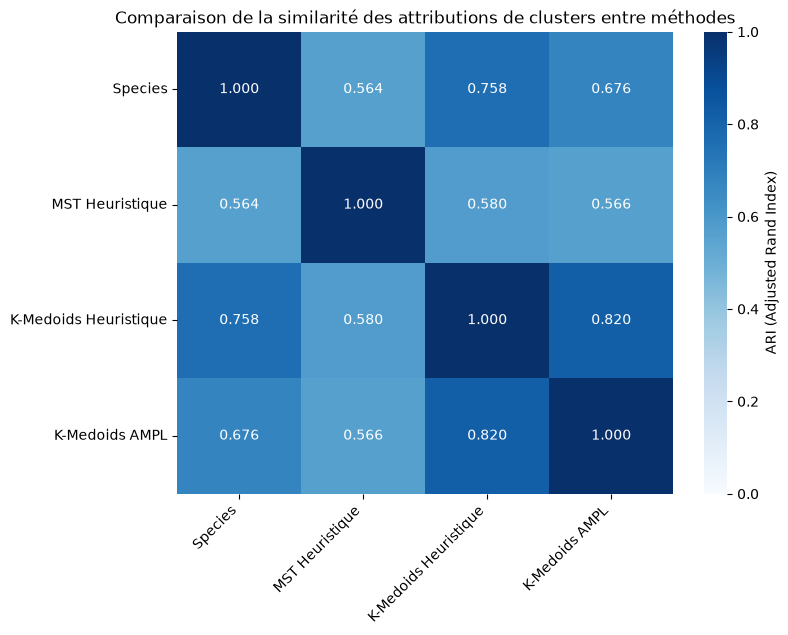

In [ ]:
from sklearn.metrics import adjusted_rand_score, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering
from scipy.optimize import linear_sum_assignment


# Load sample dataset (or your custom data X)
iris = load_iris()
X = iris.data
y = iris.target
k = 3

# Results of the different methods
df_labels = pd.read_csv("iris_labels.txt", header=None)
ampl_labels = df_labels.iloc[:, 0].values

kmedoids = KMedoids(n_clusters=3, random_state=42)
kmedoids.fit(X)
labels_heur_kmed = kmedoids.labels_

mst_clustering = AgglomerativeClustering(n_clusters=3, linkage="single")
labels_heur_mst = mst_clustering.fit_predict(X)


def align_cluster_labels(y_true, y_pred):
  """Ré-indexe les labels de y_pred pour correspondre au mieux à y_true (correction des permutations)."""
  cm = confusion_matrix(y_true, y_pred)
  # Utilisation de l'algorithme hongrois pour trouver la meilleure correspondance de colonnes
  row_ind, col_ind = linear_sum_assignment(-cm)
  # Création d'un mapping des anciens vers les nouveaux labels
  mapping = {col: row for row, col in zip(row_ind, col_ind)}
  return np.array([mapping[label] for label in y_pred])

# --- 1. CHARGEMENT DES DIFFÉRENTS LABELS ---
# Supposons que vous avez vos tableaux numpy de taille (150,) pour chaque méthode :
# - y : v
# - labels_heur_mst : résultat de votre heuristique MST
# - labels_heur_kmed : résultat de votre heuristique k-médoides
# - ampl_labels : résultat exact AMPL (chargé via votre fichier précédent)

# Exemple de dictionnaire pour regrouper toutes vos méthodes facilement :
methods = {
    "Species": y,
    "MST Heuristique": labels_heur_mst,
    "K-Medoids Heuristique": labels_heur_kmed,
    "K-Medoids AMPL": ampl_labels,
}



# --- 2. CALCUL DE LA MATRICE DE SIMILARITÉ (ARI) ---
# L'ARI vaut 1 si les classifications sont identiques, et ~0 (ou négatif) si indépendantes.
n_methods = len(methods)
method_names = list(methods.keys())
ari_matrix = np.zeros((n_methods, n_methods))

for i, name1 in enumerate(method_names):
    for j, name2 in enumerate(method_names):
        ari_matrix[i, j] = adjusted_rand_score(methods[name1], methods[name2])

# Conversion en DataFrame Pandas pour un affichage propre
df_ari = pd.DataFrame(ari_matrix, index=method_names, columns=method_names)
print("--- Matrice des Indices de Rand Ajustés (ARI) ---")
display(df_ari)

# --- 3. VISUALISATION GRAPHIQUE (Heatmap de comparaison) ---
plt.figure(figsize=(8, 6))
sns.heatmap(
    df_ari,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "ARI (Adjusted Rand Index)"},
)
plt.title(
    "Comparaison de la similarité des attributions de clusters entre méthodes"
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

# Enregistrement de l'image de comparaison
plt.savefig("comparaison_clustering_ari.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Dictionnaire regroupant vos labels existants
methods = {
    "K-Medoids AMPL (Optimal)": ampl_labels,
    "K-Medoids Heuristique": labels_heur_kmed,
    "MST Heuristique (SciPy)": labels_heur_mst,
}

# --- 1. CALCUL DE L'INDICE DE RAND AJUSTÉ (ARI) ---
print("=== INDICE DE RAND AJUSTÉ (ARI) par rapport à y ===")
for name, labels in methods.items():
  ari = adjusted_rand_score(y, labels)
  print(f"{name} : ARI = {ari:.4f}")


# --- 2. FONCTION DE RÉALIGNEMENT DES CLUSTERS ---
def align_cluster_labels(y_true, y_pred):
  cm = confusion_matrix(y_true, y_pred)
  row_ind, col_ind = linear_sum_assignment(-cm)
  mapping = {col: row for row, col in zip(row_ind, col_ind)}
  # Sécurité : si un label n'est pas dans le mapping, on le laisse tel quel
  return np.array([mapping.get(label, label) for label in y_pred])


# --- 3. AFFICHAGE ET ENREGISTREMENT DES MATRICES DE CONFUSION ---
fig, axes = plt.subplots(1, len(methods), figsize=(16, 4))

for ax, (name, labels) in zip(axes, methods.items()):
  # Réalignement pour éviter les problèmes de numérotation des classes
  labels_aligned = align_cluster_labels(y, labels)
  cm = confusion_matrix(y, labels_aligned)

  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      cbar=False,
      ax=ax,
      annot_kws={"size": 12},
  )
  ax.set_title(f"Vraies classes (y) vs {name}")
  ax.set_xlabel("Clusters trouvés (réalignés)")
  ax.set_ylabel("Vraies classes (y)")

plt.tight_layout()
plt.savefig("comparaison_matrices_confusion_y.png", dpi=300, bbox_inches="tight")
plt.show()

NameError: name 'ampl_labels' is not defined